In [4]:
import matplotlib.pyplot as plt
import numpy as np


In [199]:
from anemone.forwards import *

def waveform_matrix_with_primary(t_in, t_out, waveform):
    t_out = t_out.to(torch.double)
    t_in  = t_in.to(torch.double)

    logT = torch.log(t_in)
    dT = torch.diff(logT, prepend=logT[1:2]-2*logT[:1])
    # dT = logT[1]-logT[0]
    #dT = torch.roll(dT, 1)  # Shift to align with t_in

    t2t = torch.zeros(t_out.shape+(len(t_in)+1,), device=t_in.device, dtype=t_out.dtype)

    for t_wv,k_wv in zip(waveform.time, waveform.d2wdt2):
        c_t_eval = t_out - t_wv
        positive_time = c_t_eval >= 0.
        t2t[~positive_time , 0] += k_wv
        t2t[ positive_time, 1:] += k_wv*lamontagne((torch.log(c_t_eval[positive_time])[:,None]-logT[None,:])/dT[None,:])
    return t2t

class BstepLaplace(ForwardLaplace):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.t_eval = self.times
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        if receiver.z.numel()>1:
            self.rz = receiver.z.flatten()[0]
            assert torch.all(receiver.z==self.rz), "Receiver z coordinates are not the same"
        else:
            self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)    
        self.device = times.device
        self.tolerance = tolerance

    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.s_lap = s[None, None, :]
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz)
                intg = rtelap(self.sigma, self.thick, self.s_lap, self.lmb)*self.sfield_rte
                intg /= -self.s_lap
                return torch.squeeze(intg).real
            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            res[None, ...] *= self.lmb / c.fourpi
            return res.swapaxes(-2,-1)
        if self.geomz is None:
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=16, tolerance=self.tolerance)
            def geomz_r(r):
                return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
            Hstep, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
            self.sfield_rte = None
        else:
            Hstep = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
        return Hstep
        
    def __call__(self, rho, thickness):
        self.rho = rho
        self.thick = thickness
        return self.forward().squeeze()*c.mu0
    
class BstepHankel(BaseForward):
    geomz=None
    sfield_rte=None
    lmb=None
    tout=None
    def __init__(self, source, receiver, tmin, tmax, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.tmin = tmin
        self.tmax = tmax
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(tmin.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(tmin.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.device = tmin.device
        if receiver.z.numel()>1:
            self.rz = receiver.z.flatten()[0]
            assert torch.all(receiver.z==self.rz), "Receiver z coordinates are not the same"
        else:
            self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)
        self.tolerance = tolerance
    
    def calc_bstep(self):
        def frq_integrand(f):
            omega = c.twopi*f[None,:,None]

            def wvlngth_integrand(wave_length):
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-wave_length*self.sfield_dz)
                intg = rte(self.sigma, self.thick, omega, wave_length[None,None,:])*self.sfield_rte*wave_length
                return intg
            
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=10, tolerance=self.tolerance)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hstep, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
                self.sfield_rte = None
            else:
                Hstep = (wvlngth_integrand(self.lmb.squeeze())@self.geomz).squeeze()
            Hstep /= -1j*omega.squeeze()
            return Hstep.squeeze()
        ift = invFourier(frq_integrand, smp_per_decade=16, device=self.device)
        # ift._recenter_function((self.tmax/self.tmin, 1e12*self.tmax/self.tmin))
        # print(f"Recentered function to {torch.sqrt((self.tmax/self.tmin)*(self.tmax/self.tmin*1e12))}")
        self.tout, Hstep = ift.range(self.tmin, self.tmax)
        return Hstep/c.fourpi

   
    def get_bstep(self, rho, thickness):
        self.rho = rho
        self.thick = thickness
        # t,bstep = self.calc_bstep()
        # return t, bstep.squeeze()*c.mu0
        bstep = self.calc_bstep()
        return self.tout, bstep.squeeze()*c.mu0
    
class OnTimeForward:
    hankel = None
    laplace = None
    t2t = None

    def __init__(self, source, receiver, times, waveform, tolerance=None, t_smp_per_decade=10):
        self.source = source
        self.receiver = receiver
        self.times = times
        self.tmin = times.min().to(torch.double)
        self.tmax = times.max().to(torch.double)
        self.device = times[0].device
        from biotsavart import Loop, ObsPoint, calc_bfield
        _loop = Loop(self.source.x.numpy(), self.source.y.numpy(), self.source.z.numpy())
        _obs = ObsPoint(self.receiver.x.numpy(), self.receiver.y.numpy(), self.receiver.z.numpy())
        self.pfield = torch.from_numpy(calc_bfield(_loop.xyz, _obs.xyz)[..., 2]).reshape([1])# / c.mu0

        self.rmin = self.source.min_horizontal_distance(self.receiver).to(self.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(self.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()[0]
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)

        self.waveform = waveform
        self.tmin += -self.waveform.time.max()
        self.tmax += -self.waveform.time.min()
        waveform.time = waveform.time.to(self.device)
        waveform.amplitude = waveform.amplitude.to(self.device)
        waveform.d2wdt2 = waveform.d2wdt2.to(self.device)
        self.t_smp_per_decade = t_smp_per_decade
        self.t_switch = torch.tensor([1e-3])
        
        

        self.tolerance=tolerance
        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))
        
    def forward(self):
        if self.hankel is None:
            self.hankel = BstepHankel(self.source, self.receiver, self.t_switch, self.tmax)

        t, bstep_hankel = self.hankel.get_bstep(self.rho, self.thick)
        dt = t[1]/t[0]
        Ndec = int(torch.log10(t[0]/1e-11)/torch.log10(dt))+1
        # print(f"Number of decades in Laplace: {Ndec}, dt={dt}, t[0]={t[0]}")
        self.t_laplace = t[0]*dt**torch.arange(-Ndec, 0)

        if self.laplace is None:
            self.laplace = BstepLaplace(self.source, self.receiver, self.t_laplace)
        bstep_laplace = self.laplace(self.rho, self.thick)
        if self.t2t is None:
            self.t_in = torch.concat([self.t_laplace, t])
            self.t2t = waveform_matrix_with_primary(self.t_in, self.times, self.waveform)
            self.t2t[:,1] = 0.
        self.bstep = torch.concat([self.pfield, bstep_laplace, bstep_hankel]).real
        return self.t2t @ self.bstep

    def __call__(self, rho, thickness):
        self.rho = rho[..., None, None]
        if rho.ndim > thickness.ndim:
            thickness = thickness[:, None, ...]
        self.thick = thickness[..., None, None]
        return self.forward()


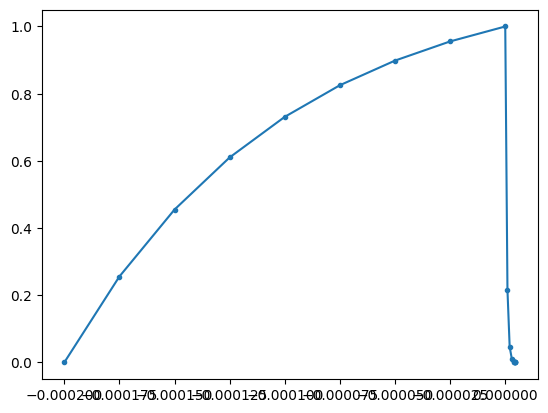

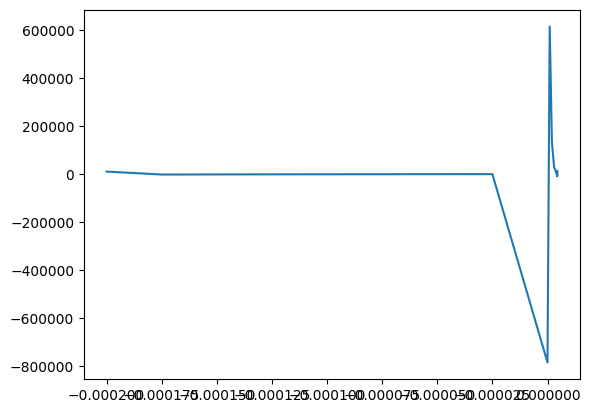

In [200]:
from anemone.system import Waveform

DEFAULT_WAVE_T = np.array([
    -2.00e-04, -1.75e-04, -1.50e-04, -1.25e-04, -1.00e-04, -7.50e-05,
    -5.00e-05, -2.50e-05,  0.00e+00,  1.00e-06,  2.00e-06,  3.00e-06,
     4.00e-06,  4.10e-06,  4.20e-06,  4.30e-06,  4.40e-06,  4.50e-06,
])
DEFAULT_WAVE_A = np.array([0.00000, 0.25582, 0.45505, 0.61022, 0.73106, 0.82517,
    0.89846, 0.95555, 1.00000, 0.21544, 0.046416, 0.01000,
    0.0021544, 0.0018478, 0.0015849, 0.0013594, 0.0011659, 0.00000,
])

wv = Waveform(DEFAULT_WAVE_T, DEFAULT_WAVE_A)

plt.figure()
plt.plot(DEFAULT_WAVE_T, DEFAULT_WAVE_A, '.-')

plt.figure()
plt.plot(wv.time, wv.d2wdt2)

wv0 = Waveform.example()
DEFAULT_WAVE_T = wv0.time
DEFAULT_WAVE_A = wv0.amplitude

from scipy.interpolate import interp1d
wv_int = interp1d(DEFAULT_WAVE_T, DEFAULT_WAVE_A, kind='cubic', bounds_error=False, fill_value=0.0)
wave_t = DEFAULT_WAVE_T
wave_a = DEFAULT_WAVE_A

wave_t = np.linspace(DEFAULT_WAVE_T.min(), DEFAULT_WAVE_T.max(), 2000)
wave_a = wv_int(wave_t)
# t2t = fwr0.t2t


wv = Waveform(wave_t, wave_a)

In [201]:
from anemone.system import *

tx = Loop.square(30)
rx = Receiver()
times = torch.logspace(-11, 0, 501)

fwr0 = Forward(tx, rx, times, wv)

fwr = OnTimeForward(tx, rx, times, wv)

rho = torch.ones(2)*100
thick = torch.ones(1)*100
dbdt = fwr(rho, thick)
dbdt0 = fwr0(rho, thick)

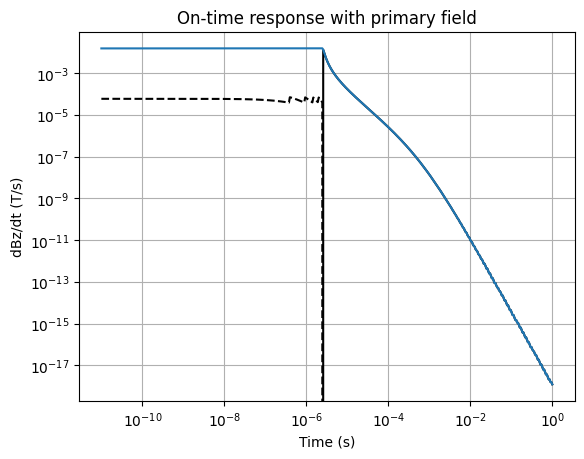

In [202]:
plt.figure()
plt.loglog(times,  dbdt0, 'k')
plt.loglog(times, -dbdt0, 'k--')

plt.loglog(times,  dbdt, 'C0')
plt.loglog(times, -dbdt, 'C0--')
# plt.loglog(times,  dbdt, 'C0.')
# plt.loglog(times, -dbdt, 'C0x')

plt.grid()
plt.xlabel("Time (s)")
plt.ylabel("dBz/dt (T/s)")
plt.title("On-time response with primary field")
# plt.xlim(1e-7, 1e-5)

t2tsave = fwr.t2t*1.
t_in    = fwr.t_in*1.

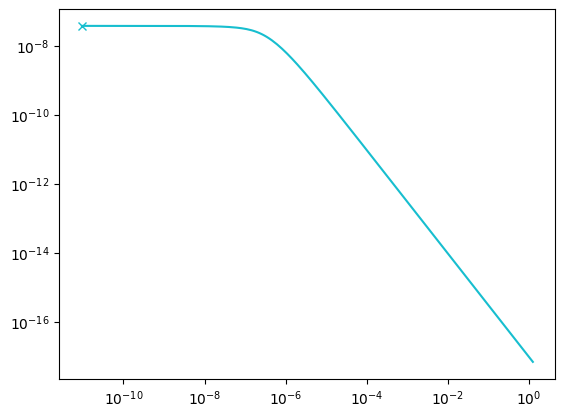

In [194]:
tx = Loop.square(3)
plt.figure()

plt.loglog(t_in,     fwr.bstep[1:], f'C{i}-')
plt.loglog(t_in,    -fwr.bstep[1:], f'C{i}--')
plt.loglog(t_in[0],  fwr.bstep[0], f'C{i}.')
plt.loglog(t_in[0], -fwr.bstep[0], f'C{i}x')

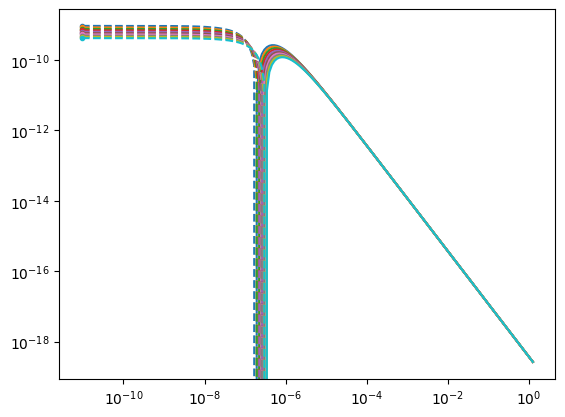

In [186]:
tx = Loop.square(3)
plt.figure()

# for i,sep in enumerate([1, 2, 4, 5, 8, 10, 15, 20]):
for i,sep in enumerate(np.linspace(10, 13, 10)):
    rx = Receiver(x=sep)
    # times = torch.logspace(-11, -3, 201)
    fwr = OnTimeForward(tx, rx, times, wv)
    fwr.t2t=t2tsave*1.


    rho = torch.ones(2)*40
    thick = torch.ones(1)*40
    dbdt = fwr(rho, thick)

    plt.loglog(t_in,     fwr.bstep[1:], f'C{i}-')
    plt.loglog(t_in,    -fwr.bstep[1:], f'C{i}--')

    plt.loglog(t_in[0],  fwr.bstep[0], f'C{i}.')
    plt.loglog(t_in[0], -fwr.bstep[0], f'C{i}x')

C:\Users\au646858\AppData\Local\Temp\ipykernel_19652\766005758.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.matshow(np.log10(np.abs(t2tsave)))
C:\Users\au646858\AppData\Local\Temp\ipykernel_19652\766005758.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.matshow(np.log10(np.abs(t2tsave)))


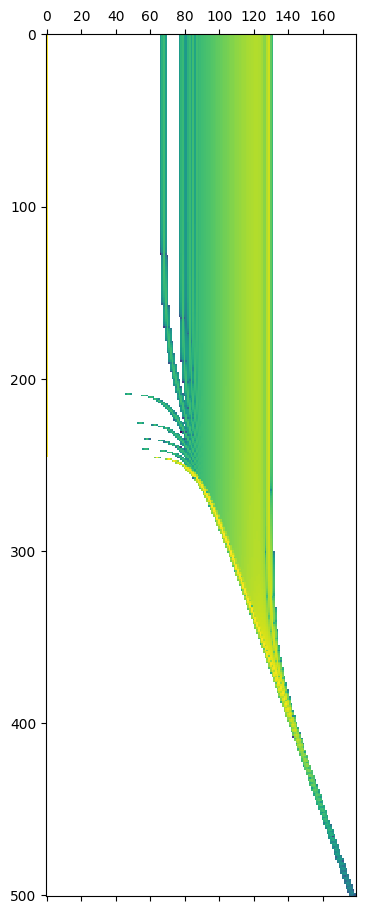

In [195]:
plt.matshow(np.log10(np.abs(t2tsave)))